In [1]:
from pathlib import Path
import os

# Find the project folder automatically
current = Path.cwd()

possible_folders = [
    current,
    *current.parents,
    current / "unemployment_project",
    current / "Documents" / "GitHub" / "nailuciana100-cell.github.io" / "unemployment_project"
]

PROJECT_FOLDER = next(
    (folder for folder in possible_folders
     if (folder / "data" / "LNS14000012.csv").is_file()),
    None
)

if PROJECT_FOLDER is None:
    raise FileNotFoundError(
        "Project folder not found. Open JupyterLab from the project folder."
    )

os.chdir(PROJECT_FOLDER)

print("Current folder:", Path.cwd())
print("Data folder exists:", Path("data").exists())
print("CSV file exists:", Path("data/LNS14000012.csv").exists())

Current folder: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project
Data folder exists: True
CSV file exists: True


In [2]:
# %% Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.precision", 4)

In [3]:
from pathlib import Path
import os
import pandas as pd

PROJECT_FOLDER = Path.cwd()
DATA_FOLDER = Path("data")

print("Current folder:", PROJECT_FOLDER)
print("Data folder exists:", DATA_FOLDER.exists())

Current folder: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project
Data folder exists: True


In [4]:
files = {
    "16-19": "LNS14000012.csv",
    "20-24": "LNS14000036.csv",
    "25-34": "LNS14000089.csv",
    "55+": "LNS14024230.csv"
}

for group, filename in files.items():
    path = DATA_FOLDER / filename
    print(group, ":", "Found" if path.exists() else "MISSING")

16-19 : Found
20-24 : Found
25-34 : Found
55+ : Found


In [5]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("Files and folders:", [p.name for p in Path.cwd().iterdir()])

Current folder: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project
Files and folders: ['.ipynb_checkpoints', 'anaconda_projects', 'data', 'model_summary.csv', 'output', 'Unemployment_analysis.ipynb', 'Unemployment_analysis_FINAL.ipynb', 'unemployment_forecast.csv']


In [6]:
from pathlib import Path

for folder in ["Downloads", "Documents", "Desktop", "OneDrive"]:
    location = Path.home() / folder

    if location.exists():
        for file in location.rglob("LNS14000012.csv"):
            print("Found:", file)

Found: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project\data\LNS14000012.csv


In [7]:
from pathlib import Path
import pandas as pd

DATA_FOLDER = Path("data")

df_16_19 = pd.read_csv(DATA_FOLDER / "LNS14000012.csv")

df_16_19.head()

,observation_date,LNS14000012
0,1948-01-01,8.5
1,1948-02-01,10.0
2,1948-03-01,10.5
3,1948-04-01,9.5
4,1948-05-01,7.0


In [8]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("Data folder exists:", Path("data").exists())

Current folder: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project
Data folder exists: True


In [9]:
df_16_19["observation_date"] = pd.to_datetime(df_16_19["observation_date"])

In [10]:
df_20_24 = pd.read_csv(DATA_FOLDER / "LNS14000036.csv")

In [11]:
df_20_24["observation_date"] = pd.to_datetime(df_20_24["observation_date"])

In [12]:
df_25_34 = pd.read_csv(DATA_FOLDER / "LNS14000089.csv")

In [13]:
df_25_34.head()

,observation_date,LNS14000089
0,1948-01-01,3.0
1,1948-02-01,3.3
2,1948-03-01,2.9
3,1948-04-01,3.4
4,1948-05-01,3.0


In [14]:
df_25_34["observation_date"] = pd.to_datetime(df_25_34["observation_date"])

In [15]:
# %% CONFIG - Project Folder

from pathlib import Path

PROJECT_FOLDER = Path(
    r"C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project"
)

DATA_FOLDER = PROJECT_FOLDER / "data"

print("Project folder:", PROJECT_FOLDER)
print("Data folder exists:", DATA_FOLDER.exists())

Project folder: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project
Data folder exists: True


In [16]:
df_55_plus = pd.read_csv(DATA_FOLDER / "LNS14024230.csv")
df_55_plus.head()

,observation_date,LNS14024230
0,1948-01-01,2.9
1,1948-02-01,3.1
2,1948-03-01,3.0
3,1948-04-01,3.0
4,1948-05-01,3.1


In [17]:
df_55_plus["observation_date"] = pd.to_datetime(
    df_55_plus["observation_date"]
)

In [18]:
df_16_19 = df_16_19.rename(columns={"LNS14000012": "unemployment_rate"})

In [19]:
df_20_24 = df_20_24.rename(columns={"LNS14000036": "unemployment_rate"})

In [20]:
df_25_34 = df_25_34.rename(columns={"LNS14000089": "unemployment_rate"})

In [21]:
df_55_plus = df_55_plus.rename(
    columns={"LNS14024230": "unemployment_rate"}
)

In [22]:
df_16_19.head()

,observation_date,unemployment_rate
0,1948-01-01,8.5
1,1948-02-01,10.0
2,1948-03-01,10.5
3,1948-04-01,9.5
4,1948-05-01,7.0


In [23]:
df_16_19["age_group"] = "16-19"

In [24]:
df_20_24["age_group"] = "20-24"

In [25]:
df_25_34["age_group"] = "25-34"

In [26]:
df_55_plus["age_group"] = "55+"

In [27]:
df = pd.concat(
    [df_16_19, df_20_24, df_25_34, df_55_plus],
    ignore_index=True
)

In [28]:
df["age_group"].value_counts()

age_group
16-19    944
20-24    944
25-34    944
55+      944
Name: count, dtype: int64

In [29]:
df.head()

,observation_date,unemployment_rate,age_group
0,1948-01-01,8.5,16-19
1,1948-02-01,10.0,16-19
2,1948-03-01,10.5,16-19
3,1948-04-01,9.5,16-19
4,1948-05-01,7.0,16-19


In [30]:
df.isnull().sum()

observation_date     0
unemployment_rate    4
age_group            0
dtype: int64

In [31]:
df[df["unemployment_rate"].isnull()]

,observation_date,unemployment_rate,age_group
933,2025-10-01,NaN,16-19
1877,2025-10-01,NaN,20-24
2821,2025-10-01,NaN,25-34
3765,2025-10-01,NaN,55+


In [32]:
df = df.dropna(subset=["unemployment_rate"])

In [33]:
df.isnull().sum()

observation_date     0
unemployment_rate    0
age_group            0
dtype: int64

In [34]:
df["age_group"].value_counts()

age_group
16-19    943
20-24    943
25-34    943
55+      943
Name: count, dtype: int64

In [35]:
# Make sure all dates have the same format
df["observation_date"] = pd.to_datetime(df["observation_date"])

# Check the first and last dates
df["observation_date"].min(), df["observation_date"].max()

(Timestamp('1948-01-01 00:00:00'), Timestamp('2026-08-01 00:00:00'))

In [36]:
df.groupby("age_group")["unemployment_rate"].describe()

,count,mean,std,min,25%,50%,75%,max
age_group,,,,,,,,
16-19,943.0,15.9040,3.9203,6.4,13.4,15.9,17.90,32.8
20-24,943.0,9.2192,2.6781,3.5,7.4,9.0,10.65,25.5
25-34,943.0,5.4537,1.8532,1.9,4.1,5.2,6.50,14.6
55+,943.0,3.7778,1.1848,1.7,3.0,3.5,4.30,13.6


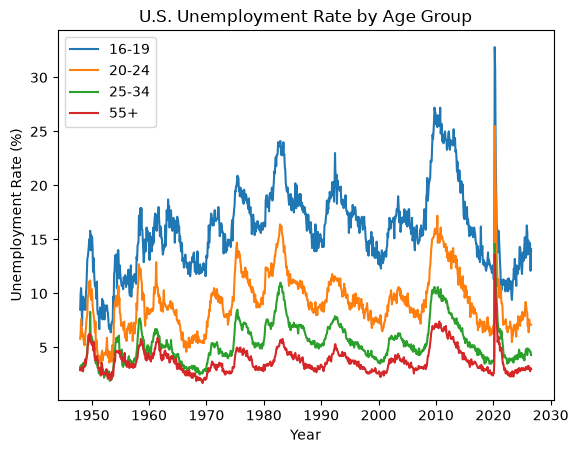

In [37]:
for group in ["16-19", "20-24", "25-34", "55+"]:
    temp = df[df["age_group"] == group]
    plt.plot(temp["observation_date"], temp["unemployment_rate"], label=group)

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.title("U.S. Unemployment Rate by Age Group")
plt.legend()
plt.show()

In [38]:
df_recent = df[df["observation_date"] >= "2000-01-01"].copy()

In [114]:
from pathlib import Path

CLEAN_FOLDER = Path("data/clean")
CLEAN_FOLDER.mkdir(parents=True, exist_ok=True)

df_recent.to_csv(
    CLEAN_FOLDER / "unemployment_clean.csv",
    index=False
)

print("Cleaned data saved successfully!")
print("Rows saved:", len(df_recent))

Cleaned data saved successfully!
Rows saved: 1276


In [39]:
df_recent.groupby("age_group").size()

age_group
16-19    319
20-24    319
25-34    319
55+      319
dtype: int64

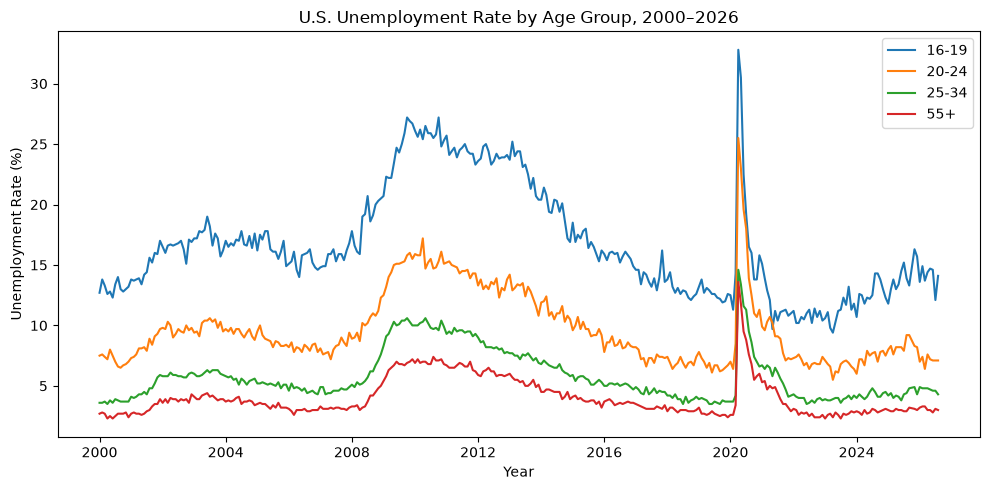

In [40]:
# %% Plot unemployment rates from 2000 onward

plt.figure(figsize=(10, 5))

for group in ["16-19", "20-24", "25-34", "55+"]:
    temp = df_recent[df_recent["age_group"] == group]
    plt.plot(
        temp["observation_date"],
        temp["unemployment_rate"],
        label=group
    )

plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.title("U.S. Unemployment Rate by Age Group, 2000–2026")
plt.legend()
plt.tight_layout()
plt.savefig("output/unemployment_rates_2000_2026.png", dpi=300, bbox_inches="tight")
plt.show()

In [41]:
teen = df_recent[df_recent["age_group"] == "16-19"].copy()

In [42]:
teen = teen.sort_values("observation_date")

In [43]:
teen = teen.set_index("observation_date")

In [44]:
teen.head()

,unemployment_rate,age_group
observation_date,,
2000-01-01,12.7,16-19
2000-02-01,13.8,16-19
2000-03-01,13.3,16-19
2000-04-01,12.6,16-19
2000-05-01,12.8,16-19


In [45]:
teen = teen.asfreq("MS")

In [46]:
teen.isnull().sum()

unemployment_rate    1
age_group            1
dtype: int64

In [47]:
# Fill the missing unemployment rate using linear interpolation
teen["unemployment_rate"] = teen["unemployment_rate"].interpolate(method="linear")

# Restore the age-group label for the missing month
teen["age_group"] = "16-19"

In [48]:
teen.isnull().sum()

unemployment_rate    0
age_group            0
dtype: int64

In [49]:
y = teen["unemployment_rate"]

In [50]:
y.head()

observation_date
2000-01-01    12.7
2000-02-01    13.8
2000-03-01    13.3
2000-04-01    12.6
2000-05-01    12.8
Freq: MS, Name: unemployment_rate, dtype: float64

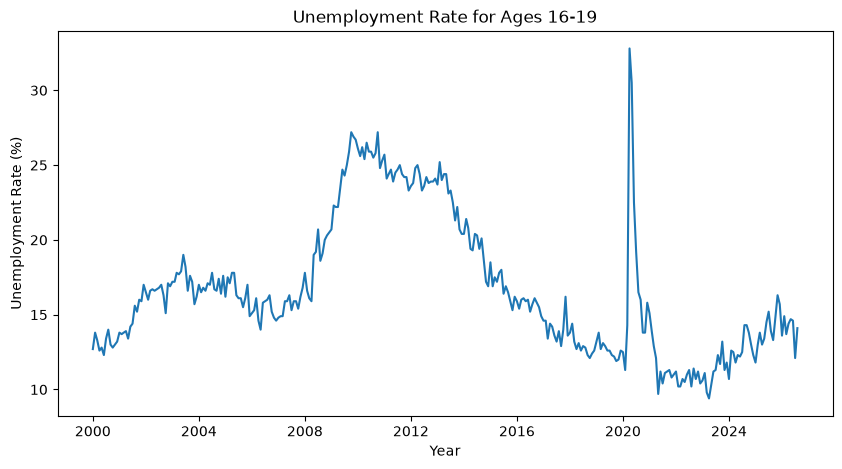

In [51]:
plt.figure(figsize=(10,5))
plt.plot(y)
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.title("Unemployment Rate for Ages 16-19")
plt.show()

In [52]:
kpss_result = kpss(y, regression="c", nlags="auto")

C:\Users\nanil\AppData\Local\Temp\ipykernel_233440\15816014.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")


In [53]:
print("KPSS Statistic:", kpss_result[0])
print("p-value:", kpss_result[1])

KPSS Statistic: 0.8247160342414955
p-value: 0.01


In [54]:
y_diff = y.diff().dropna()

In [55]:
y_diff.head()

observation_date
2000-02-01    1.1
2000-03-01   -0.5
2000-04-01   -0.7
2000-05-01    0.2
2000-06-01   -0.5
Freq: MS, Name: unemployment_rate, dtype: float64

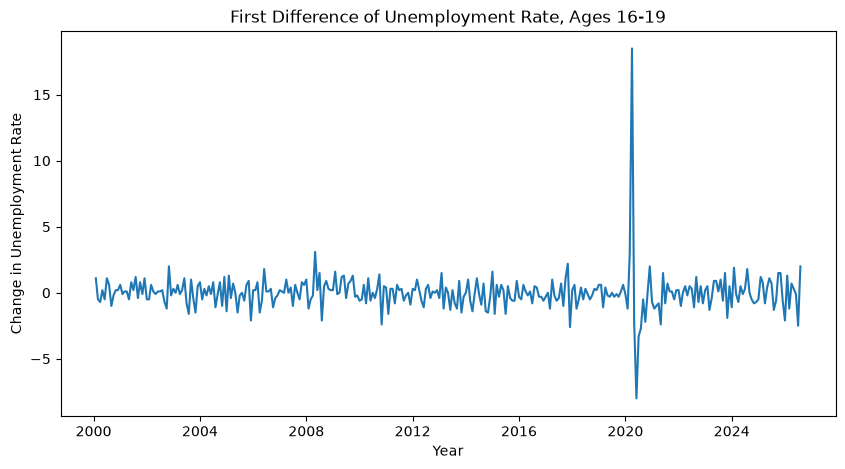

In [56]:
plt.figure(figsize=(10,5))
plt.plot(y_diff)
plt.xlabel("Year")
plt.ylabel("Change in Unemployment Rate")
plt.title("First Difference of Unemployment Rate, Ages 16-19")
plt.show()

In [57]:
kpss_diff = kpss(y_diff, regression="c", nlags="auto")

C:\Users\nanil\AppData\Local\Temp\ipykernel_233440\329924493.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_diff = kpss(y_diff, regression="c", nlags="auto")


In [58]:
print("KPSS Statistic:", kpss_diff[0])
print("p-value:", kpss_diff[1])

KPSS Statistic: 0.13212380095381254
p-value: 0.1


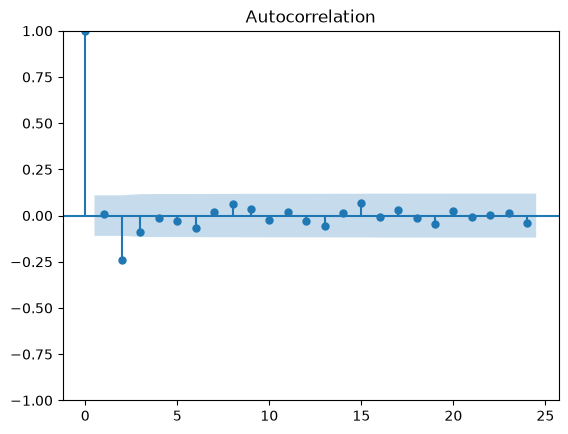

In [59]:
plot_acf(y_diff, lags=24)
plt.show()

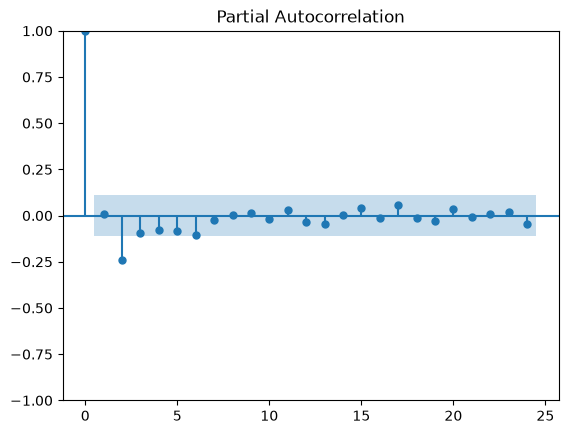

In [60]:
plot_pacf(y_diff, lags=24)
plt.show()

In [61]:
models = [(1,1,0), (2,1,0), (0,1,1), (0,1,2), (1,1,1), (2,1,2)]

for order in models:
    model = ARIMA(y, order=order)
    result = model.fit()
    print(order, "AIC =", result.aic)

(1, 1, 0) AIC = 1151.611464851946
(2, 1, 0) AIC = 1134.492417480766
(0, 1, 1) AIC = 1151.5994427496016
(0, 1, 2) AIC = 1130.5214052586125
(1, 1, 1) AIC = 1139.1129449470973
(2, 1, 2) AIC = 1130.1061365239245


In [62]:
# Prepare the monthly series and fill the missing month
y = teen["unemployment_rate"].asfreq("MS")
y = y.interpolate(method="linear")

In [63]:
y.isnull().sum()

np.int64(0)

In [64]:
models = [(1,1,0), (2,1,0), (0,1,1), (0,1,2), (1,1,1), (2,1,2)]

for order in models:
    model = ARIMA(y, order=order)
    result = model.fit()
    print(order, "AIC =", result.aic)

(1, 1, 0) AIC = 1151.611464851946
(2, 1, 0) AIC = 1134.492417480766
(0, 1, 1) AIC = 1151.5994427496016
(0, 1, 2) AIC = 1130.5214052586125
(1, 1, 1) AIC = 1139.1129449470973
(2, 1, 2) AIC = 1130.1061365239245


In [65]:
final_model = ARIMA(y, order=(2,1,2))
final_result = final_model.fit()

In [66]:
print(final_result.summary())

                               SARIMAX Results                                
Dep. Variable:      unemployment_rate   No. Observations:                  320
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -560.053
Date:                Thu, 12 Nov 2026   AIC                           1130.106
Time:                        18:32:21   BIC                           1148.932
Sample:                    01-01-2000   HQIC                          1137.625
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3970      0.250      1.587      0.112      -0.093       0.887
ar.L2         -0.0475      0.193     -0.247      0.805      -0.425       0.330
ma.L1         -0.4314      0.248     -1.739      0.0

In [67]:
residuals = final_result.resid

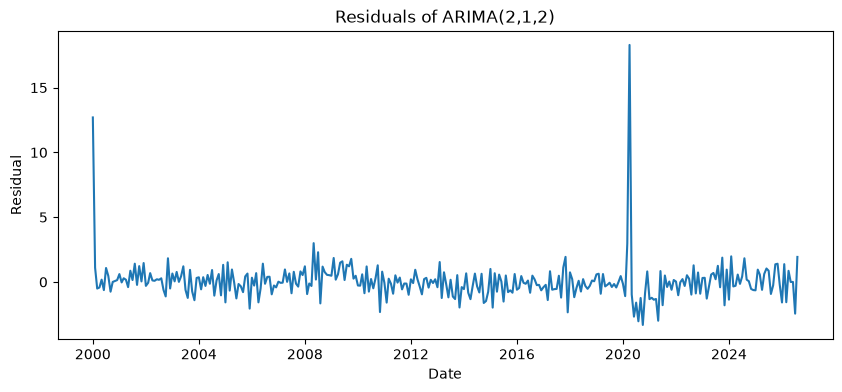

In [68]:


plt.figure(figsize=(10,4))
plt.plot(residuals)
plt.title("Residuals of ARIMA(2,1,2)")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.show()

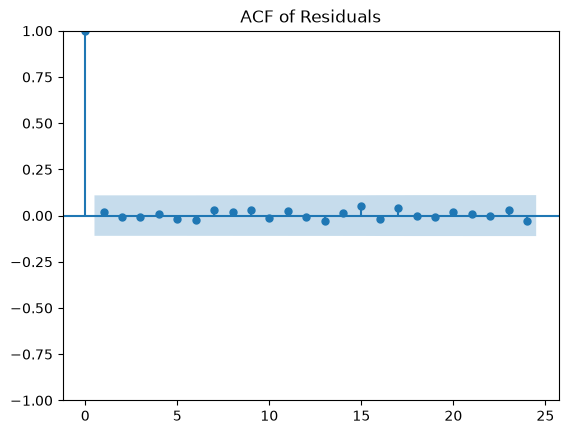

In [69]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(residuals.dropna(), lags=24)
plt.title("ACF of Residuals")
plt.show()

In [70]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box = acorr_ljungbox(residuals.dropna(), lags=[12], return_df=True)
ljung_box

,lb_stat,lb_pvalue
12,1.4963,0.9999


In [71]:
forecast = final_result.get_forecast(steps=12)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

In [72]:
forecast_mean

2026-09-01    14.7072
2026-10-01    14.4365
2026-11-01    14.3002
2026-12-01    14.2590
2027-01-01    14.2491
2027-02-01    14.2471
2027-03-01    14.2468
2027-04-01    14.2467
2027-05-01    14.2467
2027-06-01    14.2467
2027-07-01    14.2467
2027-08-01    14.2467
Freq: MS, Name: predicted_mean, dtype: float64

In [73]:
forecast_ci

,lower unemployment_rate,upper unemployment_rate
2026-09-01,11.9636,17.4508
2026-10-01,10.6227,18.2504
2026-11-01,10.0440,18.5564
2026-12-01,9.7146,18.8033
2027-01-01,9.4602,19.0379
2027-02-01,9.2312,19.2630
2027-03-01,9.0146,19.4789
2027-04-01,8.8070,19.6864
2027-05-01,8.6071,19.8864
2027-06-01,8.4141,20.0794


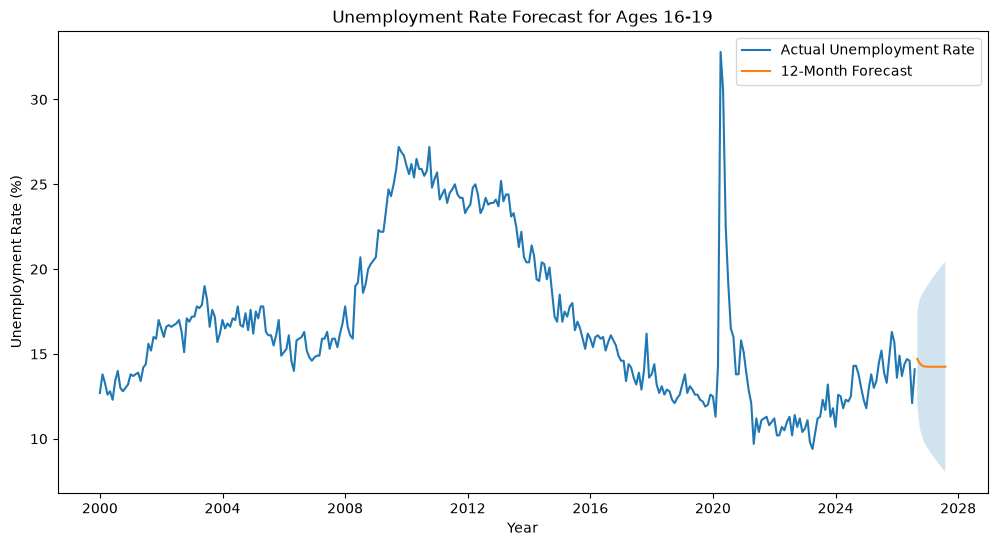

In [74]:
plt.figure(figsize=(12,6))

plt.plot(y, label="Actual Unemployment Rate")
plt.plot(forecast_mean, label="12-Month Forecast")

plt.fill_between(
    forecast_ci.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    alpha=0.2
)

plt.title("Unemployment Rate Forecast for Ages 16-19")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.show()

In [75]:
forecast_table = pd.DataFrame({
    "Forecast": forecast_mean,
    "Lower CI": forecast_ci.iloc[:, 0],
    "Upper CI": forecast_ci.iloc[:, 1]
})

forecast_table

,Forecast,Lower CI,Upper CI
2026-09-01,14.7072,11.9636,17.4508
2026-10-01,14.4365,10.6227,18.2504
2026-11-01,14.3002,10.0440,18.5564
2026-12-01,14.2590,9.7146,18.8033
2027-01-01,14.2491,9.4602,19.0379
2027-02-01,14.2471,9.2312,19.2630
2027-03-01,14.2468,9.0146,19.4789
2027-04-01,14.2467,8.8070,19.6864
2027-05-01,14.2467,8.6071,19.8864
2027-06-01,14.2467,8.4141,20.0794


In [76]:
print("First forecast:", forecast_mean.iloc[0])
print("Last forecast:", forecast_mean.iloc[-1])
print("Minimum forecast:", forecast_mean.min())
print("Maximum forecast:", forecast_mean.max())

First forecast: 14.70721793637451
Last forecast: 14.24674933584215
Minimum forecast: 14.246742729800358
Maximum forecast: 14.70721793637451


In [77]:
print("Forecast starts:", forecast_mean.index[0])
print("Forecast ends:", forecast_mean.index[-1])

Forecast starts: 2026-09-01 00:00:00
Forecast ends: 2027-08-01 00:00:00


In [78]:
# Save the teenage unemployment forecasts
OUTPUT_FOLDER = Path("output")
OUTPUT_FOLDER.mkdir(exist_ok=True)

forecast_table.to_csv(
    OUTPUT_FOLDER / "unemployment_forecast_16_19.csv"
)

In [79]:
df_2000 = df[df["observation_date"] >= "2000-01-01"]

df_2000.groupby("age_group")["unemployment_rate"].describe()

,count,mean,std,min,25%,50%,75%,max
age_group,,,,,,,,
16-19,319.0,16.7357,4.5733,9.4,13.25,15.9,19.00,32.8
20-24,319.0,9.6812,2.9972,5.5,7.40,8.9,10.80,25.5
25-34,319.0,5.7856,2.0506,3.5,4.30,5.1,6.55,14.6
55+,319.0,4.0301,1.5825,2.3,3.00,3.5,4.55,13.6


In [80]:
series = {}

for group in ["16-19", "20-24", "25-34", "55+"]:
    temp = df_2000[df_2000["age_group"] == group].copy()
    temp = temp.set_index("observation_date")
    temp = temp["unemployment_rate"].asfreq("MS")
    temp = temp.interpolate()
    series[group] = temp

In [81]:
for group, data in series.items():
    print(group, ":", len(data), "observations,", data.isnull().sum(), "missing")

16-19 : 320 observations, 0 missing
20-24 : 320 observations, 0 missing
25-34 : 320 observations, 0 missing
55+ : 320 observations, 0 missing


In [82]:
for group, data in series.items():
    result = kpss(data, regression="c", nlags="auto")
    print(group)
    print("KPSS Statistic:", result[0])
    print("p-value:", result[1])
    print()

16-19
KPSS Statistic: 0.8247160342414955
p-value: 0.01

20-24
KPSS Statistic: 0.4937188236357212
p-value: 0.04308134602799072

25-34
KPSS Statistic: 0.4454482210423706
p-value: 0.05756542196449545

55+
KPSS Statistic: 0.34003049104024696
p-value: 0.1



C:\Users\nanil\AppData\Local\Temp\ipykernel_233440\3305076794.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_233440\3305076794.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")


In [83]:

# Calculate first differences for all four age groups
series_diff = {}

for group in ["16-19", "20-24", "25-34", "55+"]:
    series_diff[group] = series[group].diff().dropna()

print("First differences calculated for all four age groups.")


First differences calculated for all four age groups.


In [84]:
for group, data in series_diff.items():
    result = kpss(data, regression="c", nlags="auto")
    print(group)
    print("KPSS Statistic:", result[0])
    print("p-value:", result[1])
    print()

16-19
KPSS Statistic: 0.13212380095381254
p-value: 0.1

20-24
KPSS Statistic: 0.04716726945234958
p-value: 0.1

25-34
KPSS Statistic: 0.05971932512808121
p-value: 0.1

55+
KPSS Statistic: 0.050019811029676085
p-value: 0.1



C:\Users\nanil\AppData\Local\Temp\ipykernel_233440\1416064163.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_233440\1416064163.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_233440\1416064163.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(data, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_233440\1416064163.py:2: InterpolationWarning: The test statistic is outside of the range of p-v

Age Group: 16-19


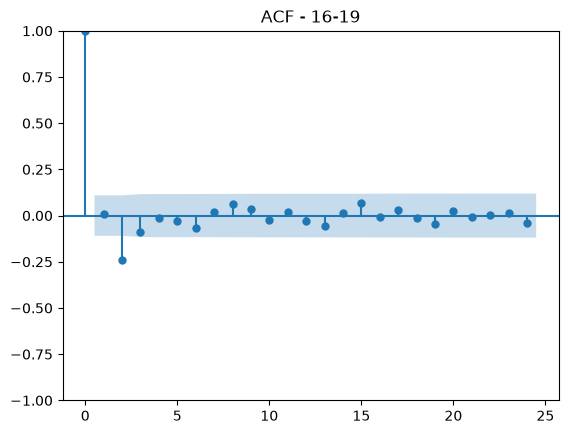

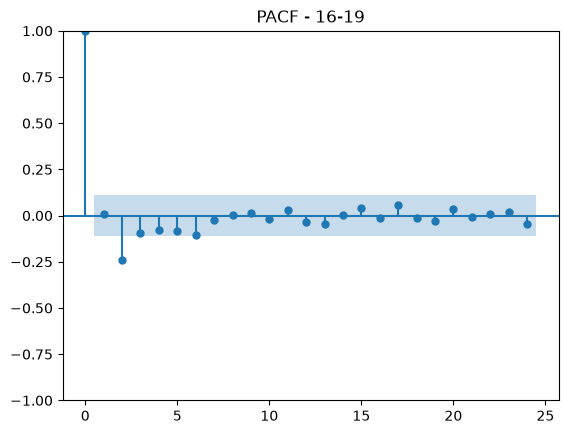

Age Group: 20-24


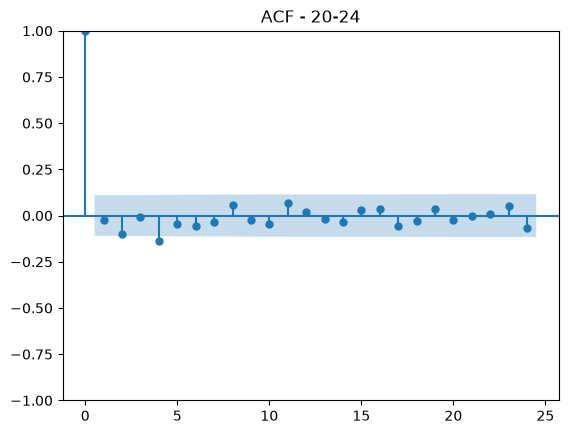

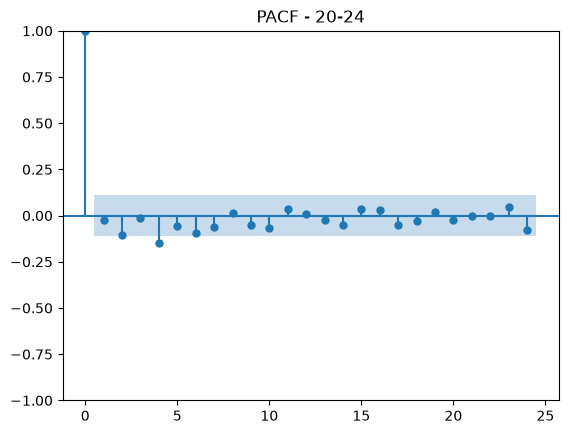

Age Group: 25-34


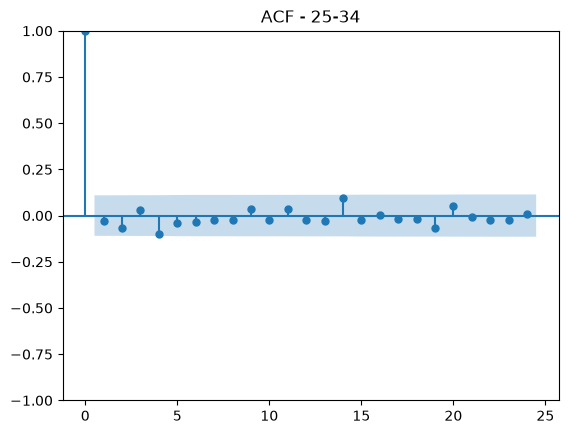

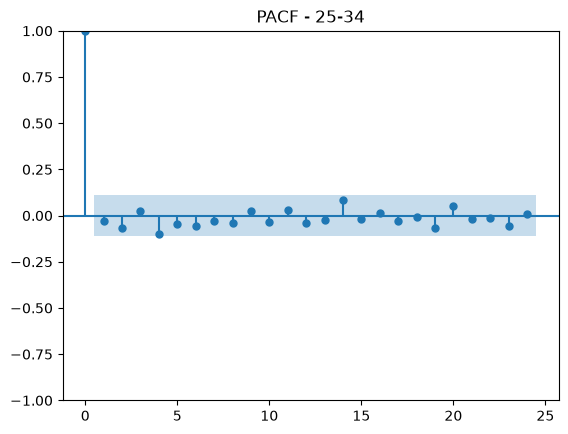

Age Group: 55+


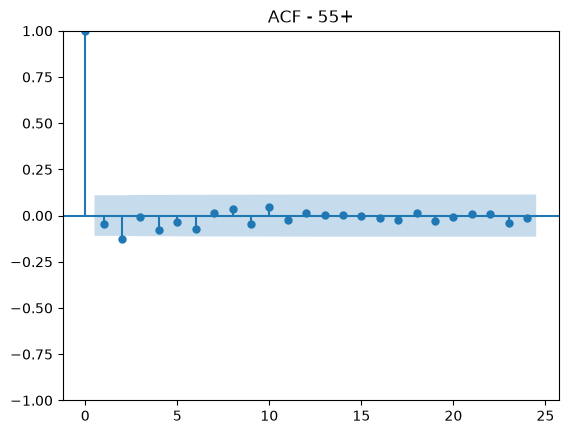

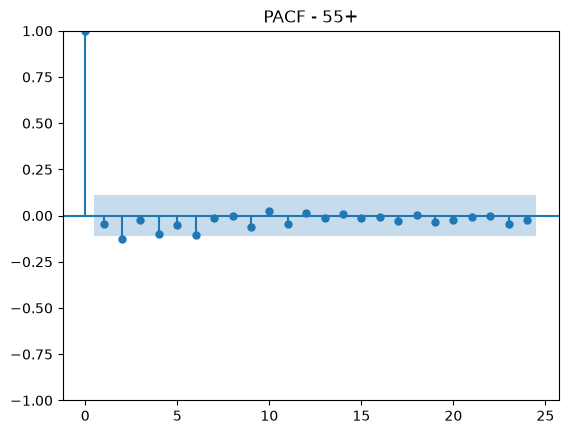

In [85]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

for group, data in series_diff.items():
    print("Age Group:", group)

    plot_acf(data, lags=24)
    plt.title("ACF - " + group)
    plt.savefig(f"output/ACF_{group}.png", dpi=300, bbox_inches="tight")
    plt.show()

    plot_pacf(data, lags=24)
    plt.title("PACF - " + group)
    plt.savefig(f"output/PACF_{group}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [86]:
from statsmodels.tsa.arima.model import ARIMA

models = [(1,1,0), (2,1,0), (0,1,1), (0,1,2), (1,1,1), (2,1,2)]

for group, data in series.items():
    print("\nAge Group:", group)
    
    for order in models:
        model = ARIMA(data, order=order)
        result = model.fit()
        print(order, "AIC =", result.aic)


Age Group: 16-19
(1, 1, 0) AIC = 1151.611464851946
(2, 1, 0) AIC = 1134.492417480766
(0, 1, 1) AIC = 1151.5994427496016
(0, 1, 2) AIC = 1130.5214052586125
(1, 1, 1) AIC = 1139.1129449470973
(2, 1, 2) AIC = 1130.1061365239245

Age Group: 20-24
(1, 1, 0) AIC = 1004.9510198185941
(2, 1, 0) AIC = 1003.596202873259
(0, 1, 1) AIC = 1004.9066192019134
(0, 1, 2) AIC = 1002.0130985601082
(1, 1, 1) AIC = 997.0134631858796


C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


(2, 1, 2) AIC = 997.7160863877198

Age Group: 25-34
(1, 1, 0) AIC = 651.0082823957856
(2, 1, 0) AIC = 651.4992563513063
(0, 1, 1) AIC = 650.958012193656
(0, 1, 2) AIC = 651.1828398984204


C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


(1, 1, 1) AIC = 647.6619621940041


C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


(2, 1, 2) AIC = 650.2685940397355

Age Group: 55+
(1, 1, 0) AIC = 633.526310322101
(2, 1, 0) AIC = 630.2654155503882
(0, 1, 1) AIC = 633.3027240937158
(0, 1, 2) AIC = 628.5797762803792
(1, 1, 1) AIC = 625.658048866658
(2, 1, 2) AIC = 627.5278858561187


In [87]:

# Compare AIC and check whether each model converged
import warnings
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

models = [(1,1,0), (2,1,0), (0,1,1),
          (0,1,2), (1,1,1), (2,1,2)]

results_list = []

for group, data in series.items():
    for order in models:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result = ARIMA(data, order=order).fit()

        results_list.append({
            "Age Group": group,
            "ARIMA": str(order),
            "AIC": round(result.aic, 3),
            "Converged": result.mle_retvals.get("converged", False)
        })

model_comparison = pd.DataFrame(results_list)
print(model_comparison.to_string(index=False))

Age Group     ARIMA      AIC  Converged
    16-19 (1, 1, 0) 1151.611       True
    16-19 (2, 1, 0) 1134.492       True
    16-19 (0, 1, 1) 1151.599       True
    16-19 (0, 1, 2) 1130.521       True
    16-19 (1, 1, 1) 1139.113       True
    16-19 (2, 1, 2) 1130.106       True
    20-24 (1, 1, 0) 1004.951       True
    20-24 (2, 1, 0) 1003.596       True
    20-24 (0, 1, 1) 1004.907       True
    20-24 (0, 1, 2) 1002.013       True
    20-24 (1, 1, 1)  997.013       True
    20-24 (2, 1, 2)  997.716       True
    25-34 (1, 1, 0)  651.008       True
    25-34 (2, 1, 0)  651.499       True
    25-34 (0, 1, 1)  650.958       True
    25-34 (0, 1, 2)  651.183       True
    25-34 (1, 1, 1)  647.662      False
    25-34 (2, 1, 2)  650.269      False
      55+ (1, 1, 0)  633.526       True
      55+ (2, 1, 0)  630.265       True
      55+ (0, 1, 1)  633.303       True
      55+ (0, 1, 2)  628.580       True
      55+ (1, 1, 1)  625.658       True
      55+ (2, 1, 2)  627.528       True


In [88]:
best_orders = {
    "16-19": (2, 1, 2),
    "20-24": (1, 1, 1),
    "25-34": (0, 1, 1),
    "55+": (1, 1, 1)
}

In [89]:
final_models = {}

for group, data in series.items():
    order = best_orders[group]
    
    model = ARIMA(data, order=order)
    result = model.fit()
    
    final_models[group] = result
    
    print("Age Group:", group)
    print("ARIMA Model:", order)
    print("AIC:", result.aic)
    print()

Age Group: 16-19
ARIMA Model: (2, 1, 2)
AIC: 1130.1061365239245

Age Group: 20-24
ARIMA Model: (1, 1, 1)
AIC: 997.0134631858796

Age Group: 25-34
ARIMA Model: (0, 1, 1)
AIC: 650.958012193656

Age Group: 55+
ARIMA Model: (1, 1, 1)
AIC: 625.658048866658



In [90]:
forecasts = {}

for group, result in final_models.items():
    forecast = result.get_forecast(steps=12)
    forecasts[group] = forecast.predicted_mean

    print("Age Group:", group)
    print(forecast.predicted_mean)
    print()

Age Group: 16-19
2026-09-01    14.7072
2026-10-01    14.4365
2026-11-01    14.3002
2026-12-01    14.2590
2027-01-01    14.2491
2027-02-01    14.2471
2027-03-01    14.2468
2027-04-01    14.2467
2027-05-01    14.2467
2027-06-01    14.2467
2027-07-01    14.2467
2027-08-01    14.2467
Freq: MS, Name: predicted_mean, dtype: float64

Age Group: 20-24
2026-09-01    7.1522
2026-10-01    7.1954
2026-11-01    7.2312
2026-12-01    7.2608
2027-01-01    7.2853
2027-02-01    7.3055
2027-03-01    7.3223
2027-04-01    7.3362
2027-05-01    7.3477
2027-06-01    7.3571
2027-07-01    7.3650
2027-08-01    7.3715
Freq: MS, Name: predicted_mean, dtype: float64

Age Group: 25-34
2026-09-01    4.311
2026-10-01    4.311
2026-11-01    4.311
2026-12-01    4.311
2027-01-01    4.311
2027-02-01    4.311
2027-03-01    4.311
2027-04-01    4.311
2027-05-01    4.311
2027-06-01    4.311
2027-07-01    4.311
2027-08-01    4.311
Freq: MS, Name: predicted_mean, dtype: float64

Age Group: 55+
2026-09-01    3.0192
2026-10-01   

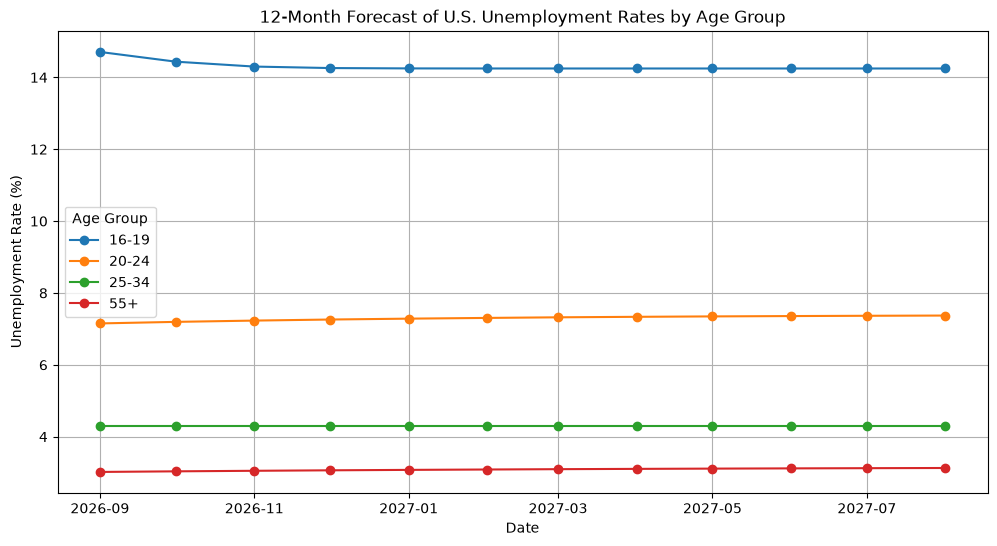

In [91]:
plt.figure(figsize=(12,6))

for group, forecast in forecasts.items():
    plt.plot(forecast.index, forecast.values, marker="o", label=group)

plt.title("12-Month Forecast of U.S. Unemployment Rates by Age Group")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="Age Group")
plt.grid(True)
plt.savefig("output/future_arima_forecasts.png", dpi=300, bbox_inches="tight")
plt.show()

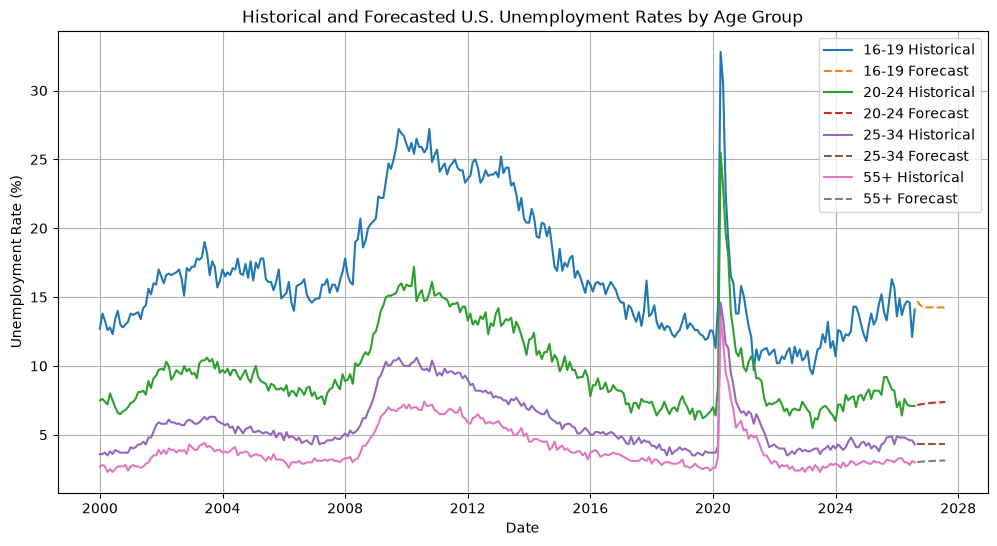

In [92]:
age_groups = ["16-19", "20-24", "25-34", "55+"]

plt.figure(figsize=(12,6))

for group in age_groups:
    historical = series[group]
    forecast = forecasts[group]

    plt.plot(historical.index, historical.values, label=f"{group} Historical")
    plt.plot(forecast.index, forecast.values, linestyle="--",
             label=f"{group} Forecast")

plt.title("Historical and Forecasted U.S. Unemployment Rates by Age Group")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(True)
plt.show()

In [93]:
test_size = 12

for group in age_groups:
    data = series[group]
    
    train = data.iloc[:-test_size]
    test = data.iloc[-test_size:]
    
    print(group)
    print("Training observations:", len(train))
    print("Testing observations:", len(test))
    print()

16-19
Training observations: 308
Testing observations: 12

20-24
Training observations: 308
Testing observations: 12

25-34
Training observations: 308
Testing observations: 12

55+
Training observations: 308
Testing observations: 12



In [94]:

# Evaluate the selected ARIMA models using the last 12 months
model_orders = best_orders

test_predictions = {}

for group in ["16-19", "20-24", "25-34", "55+"]:
    data = series[group]

    train = data.iloc[:-12]
    test = data.iloc[-12:]

    model = ARIMA(train, order=model_orders[group])
    fitted_model = model.fit()

    predictions = fitted_model.forecast(steps=12)
    test_predictions[group] = predictions

    print(group)
    print("ARIMA model:", model_orders[group])
    print("Forecast complete")
    print()



16-19
ARIMA model: (2, 1, 2)
Forecast complete

20-24
ARIMA model: (1, 1, 1)
Forecast complete

25-34
ARIMA model: (0, 1, 1)
Forecast complete

55+
ARIMA model: (1, 1, 1)
Forecast complete



In [95]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

for group in age_groups:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    print("Age Group:", group)
    print("MAE:", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print()

Age Group: 16-19
MAE: 0.968
RMSE: 1.215

Age Group: 20-24
MAE: 1.031
RMSE: 1.181

Age Group: 25-34
MAE: 0.332
RMSE: 0.361

Age Group: 55+
MAE: 0.154
RMSE: 0.18



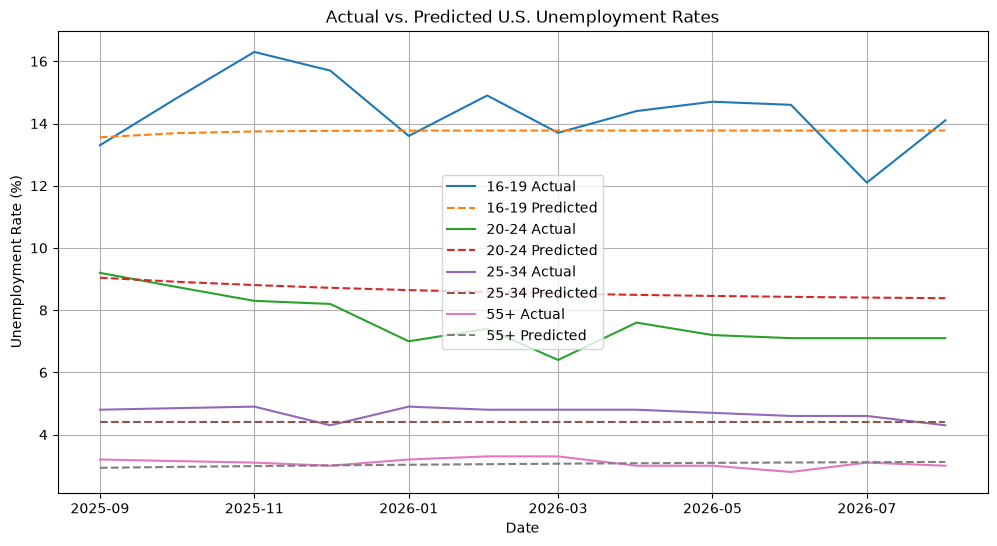

In [96]:
plt.figure(figsize=(12,6))

for group in age_groups:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    plt.plot(actual.index, actual.values,
             label=f"{group} Actual")

    plt.plot(actual.index, predicted.values,
             linestyle="--",
             label=f"{group} Predicted")

plt.title("Actual vs. Predicted U.S. Unemployment Rates")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(True)
plt.savefig("output/actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

In [97]:
accuracy_results = []

for group in age_groups:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    accuracy_results.append({
        "Age Group": group,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3)
    })

accuracy_table = pd.DataFrame(accuracy_results)

accuracy_table

,Age Group,MAE,RMSE
0,16-19,0.968,1.215
1,20-24,1.031,1.181
2,25-34,0.332,0.361
3,55+,0.154,0.180


In [98]:
residuals = {}

for group in ["16-19", "20-24", "25-34", "55+"]:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    residuals[group] = actual.values - predicted.values

    print("Age Group:", group)
    print("Mean Forecast Error:", round(residuals[group].mean(), 3))
    print()

Age Group: 16-19
Mean Forecast Error: 0.606

Age Group: 20-24
Mean Forecast Error: -1.005

Age Group: 25-34
Mean Forecast Error: 0.3

Age Group: 55+
Mean Forecast Error: 0.05



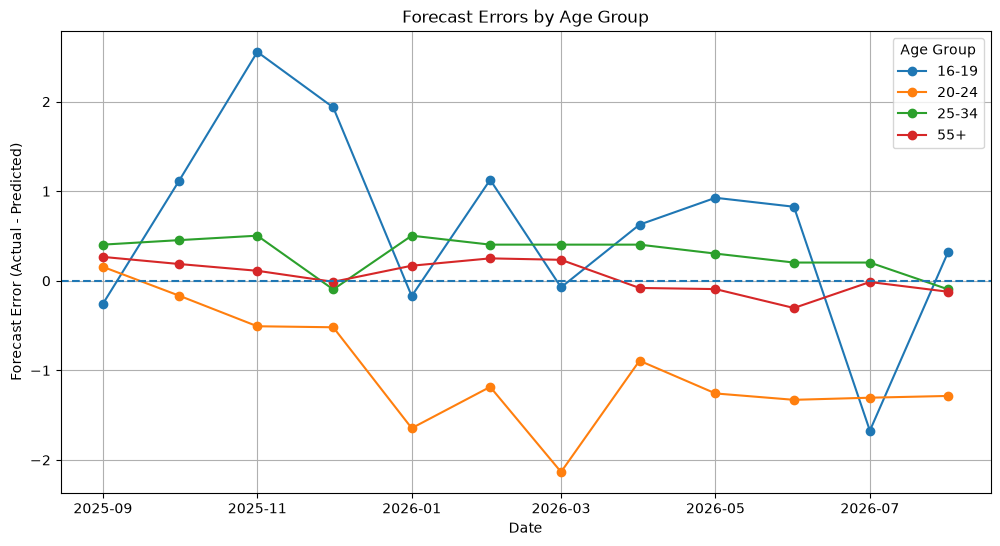

In [99]:
# Plot forecast errors for all four age groups
plt.figure(figsize=(12, 6))

for group in ["16-19", "20-24", "25-34", "55+"]:
    dates = series[group].iloc[-12:].index

    plt.plot(
        dates,
        residuals[group],
        marker="o",
        label=group
    )

plt.axhline(y=0, linestyle="--")
plt.title("Forecast Errors by Age Group")
plt.xlabel("Date")
plt.ylabel("Forecast Error (Actual - Predicted)")
plt.legend(title="Age Group")
plt.grid(True)
plt.show()



In [100]:
# Ljung-Box test for fitted ARIMA model residuals
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box_results = {}

for group in ["16-19", "20-24", "25-34", "55+"]:
    model_residuals = final_models[group].resid.iloc[1:]

    result = acorr_ljungbox(
        model_residuals,
        lags=[12],
        return_df=True
    )

    p_value = result["lb_pvalue"].iloc[0]
    ljung_box_results[group] = p_value

    print("Age Group:", group)
    print("Ljung-Box p-value:", round(p_value, 4))
    print()



Age Group: 16-19
Ljung-Box p-value: 0.9969

Age Group: 20-24
Ljung-Box p-value: 0.696

Age Group: 25-34
Ljung-Box p-value: 0.83

Age Group: 55+
Ljung-Box p-value: 0.8633



In [101]:
# Create an updated model comparison table
summary_results = []

for group in ["16-19", "20-24", "25-34", "55+"]:
    actual = series[group].iloc[-12:]
    predicted = test_predictions[group]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mean_error = np.mean(actual.values - predicted.values)

    summary_results.append({
        "Age Group": group,
        "ARIMA Model": str(best_orders[group]),
        "AIC": round(final_models[group].aic, 3),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "Mean Forecast Error": round(mean_error, 3),
        "Ljung-Box p-value": round(ljung_box_results[group], 4)
    })

summary_table = pd.DataFrame(summary_results)
summary_table


,Age Group,ARIMA Model,AIC,MAE,RMSE,Mean Forecast Error,Ljung-Box p-value
0,16-19,"(2, 1, 2)",1130.106,0.968,1.215,0.606,0.9969
1,20-24,"(1, 1, 1)",997.013,1.031,1.181,-1.005,0.6960
2,25-34,"(0, 1, 1)",650.958,0.332,0.361,0.300,0.8300
3,55+,"(1, 1, 1)",625.658,0.154,0.180,0.050,0.8633


In [102]:
# Save the updated model summary table
from pathlib import Path

OUTPUT_FOLDER = Path("output")
OUTPUT_FOLDER.mkdir(exist_ok=True)

summary_table.to_csv(
    OUTPUT_FOLDER / "model_summary.csv",
    index=False
)

print("Model summary saved successfully!")

Model summary saved successfully!


In [103]:
summary_stats = pd.DataFrame(series).describe().T
summary_stats

,count,mean,std,min,25%,50%,75%,max
16-19,320.0,16.7297,4.5674,9.4,13.275,15.90,19.000,32.8
20-24,320.0,9.6783,2.9929,5.5,7.400,8.85,10.800,25.5
25-34,320.0,5.7827,2.0481,3.5,4.300,5.10,6.525,14.6
55+,320.0,4.0273,1.5808,2.3,3.000,3.50,4.525,13.6


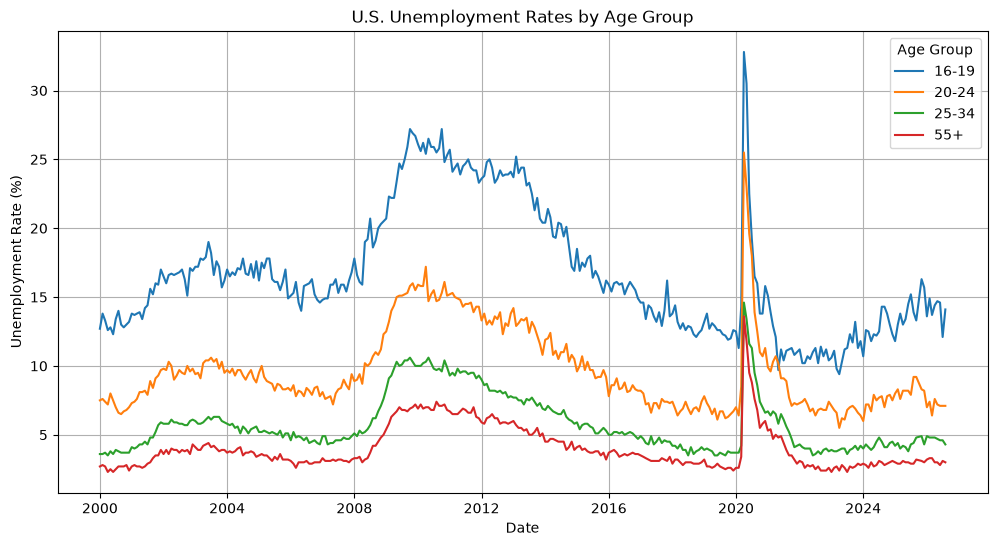

In [104]:
plt.figure(figsize=(12,6))

for group, data in series.items():
    plt.plot(data.index, data.values, label=group)

plt.title("U.S. Unemployment Rates by Age Group")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="Age Group")
plt.grid(True)
plt.show()

In [105]:
print("Age groups:", list(series.keys()))
print("Models fitted:", len(final_models))
print("Forecasts created:", len(forecasts))
print("Summary table:", summary_table.shape)
print("Data folder exists:", DATA_FOLDER.exists())

Age groups: ['16-19', '20-24', '25-34', '55+']
Models fitted: 4
Forecasts created: 4
Summary table: (4, 7)
Data folder exists: True


In [106]:
print("Forecast age groups:", list(forecasts.keys()))

Forecast age groups: ['16-19', '20-24', '25-34', '55+']


In [107]:
from pathlib import Path
import pandas as pd

OUTPUT_FOLDER = Path("output")
OUTPUT_FOLDER.mkdir(exist_ok=True)

for group, forecast in forecasts.items():
    filename = f"unemployment_forecast_{group.replace('-', '_').replace('+', 'plus')}.csv"
    forecast.to_csv(OUTPUT_FOLDER / filename)

print("All four forecasts saved!")
print("Files:", [p.name for p in OUTPUT_FOLDER.glob("unemployment_forecast_*.csv")])

All four forecasts saved!
Files: ['unemployment_forecast_16_19.csv', 'unemployment_forecast_20_24.csv', 'unemployment_forecast_25_34.csv', 'unemployment_forecast_55plus.csv']


In [108]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("Output folder:", OUTPUT_FOLDER.resolve())
print("Saved files:")

for file in OUTPUT_FOLDER.glob("*.csv"):
    print(file.name)

Current folder: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project
Output folder: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project\output
Saved files:
model_summary.csv
unemployment_forecast_16_19.csv
unemployment_forecast_20_24.csv
unemployment_forecast_25_34.csv
unemployment_forecast_55plus.csv


In [109]:
from pathlib import Path

folder = Path.cwd() / "output"

print("Output folder:", folder)
print("Files found:")

for file in folder.iterdir():
    print(file.name)

Output folder: C:\Users\nanil\Documents\GitHub\nailuciana100-cell.github.io\unemployment_project\output
Files found:
.ipynb_checkpoints
ACF_16-19.png
ACF_20-24.png
ACF_25-34.png
ACF_55+.png
actual_vs_predicted.png
arima_residuals.png
future_arima_forecasts.png
model_summary.csv
PACF_16-19.png
PACF_20-24.png
PACF_25-34.png
PACF_55+.png
unemployment_forecast_16_19.csv
unemployment_forecast_20_24.csv
unemployment_forecast_25_34.csv
unemployment_forecast_55plus.csv
unemployment_rates_2000_2026.png


In [110]:
from pathlib import Path

png_files = list(Path("output").glob("*.png"))

print("Number of saved graphs:", len(png_files))

for file in png_files:
    print(file.name)

Number of saved graphs: 12
ACF_16-19.png
ACF_20-24.png
ACF_25-34.png
ACF_55+.png
actual_vs_predicted.png
arima_residuals.png
future_arima_forecasts.png
PACF_16-19.png
PACF_20-24.png
PACF_25-34.png
PACF_55+.png
unemployment_rates_2000_2026.png


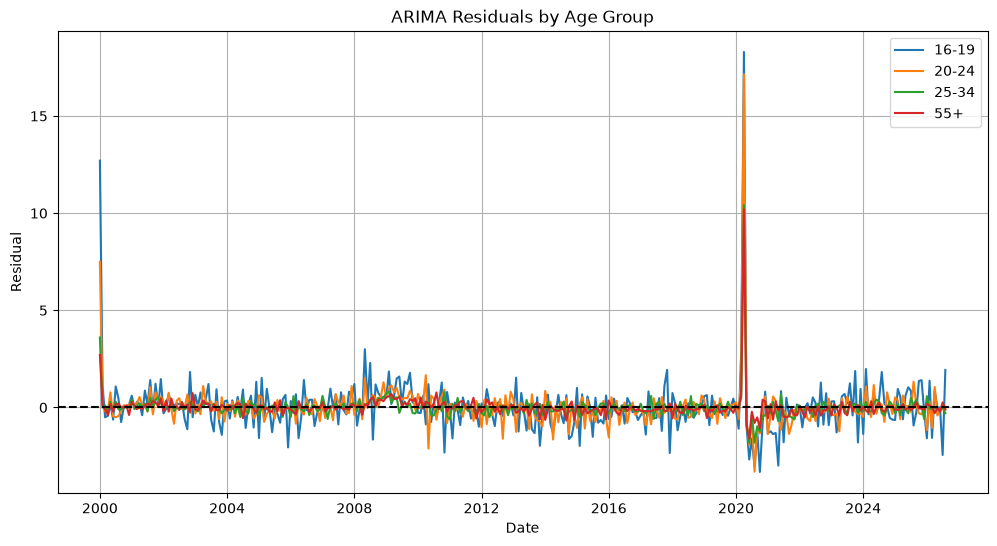

In [111]:
plt.figure(figsize=(12, 6))

for group in age_groups:
    residuals = final_models[group].resid
    plt.plot(residuals.index, residuals, label=group)

plt.axhline(0, color="black", linestyle="--")
plt.title("ARIMA Residuals by Age Group")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.legend()
plt.grid(True)

plt.savefig("output/arima_residuals.png", dpi=300, bbox_inches="tight")
plt.show()

In [112]:
print("FINAL MODEL CHECK")

for group in ["16-19", "20-24", "25-34", "55+"]:
    print(
        group,
        "Model:", final_models[group].model.order,
        "AIC:", round(final_models[group].aic, 3)
    )

FINAL MODEL CHECK
16-19 Model: (2, 1, 2) AIC: 1130.106
20-24 Model: (1, 1, 1) AIC: 997.013
25-34 Model: (0, 1, 1) AIC: 650.958
55+ Model: (1, 1, 1) AIC: 625.658


In [113]:
from pathlib import Path
import shutil

DATA_FOLDER = Path("data")
RAW_FOLDER = DATA_FOLDER / "raw"

RAW_FOLDER.mkdir(exist_ok=True)

for csv_file in DATA_FOLDER.glob("*.csv"):
    shutil.copy2(csv_file, RAW_FOLDER / csv_file.name)
    print("Copied:", csv_file.name)

print("Files in raw folder:", len(list(RAW_FOLDER.glob("*.csv"))))

Copied: LNS14000012.csv
Copied: LNS14000036.csv
Copied: LNS14000089.csv
Copied: LNS14024230.csv
Files in raw folder: 4


In [1]:
import pandas as pd

forecast = pd.read_csv("output/unemployment_forecast_16_19.csv")

print(forecast.columns.tolist())
print(forecast.head())

['Unnamed: 0', 'predicted_mean']
   Unnamed: 0  predicted_mean
0  2026-09-01       14.707218
1  2026-10-01       14.436541
2  2026-11-01       14.300211
3  2026-12-01       14.258952
4  2027-01-01       14.249053


In [2]:
from pathlib import Path

for file in Path("output").glob("*.csv"):
    print(file.name)
    print(pd.read_csv(file).columns.tolist())
    print()

model_summary.csv
['Age Group', 'ARIMA Model', 'AIC', 'MAE', 'RMSE', 'Mean Forecast Error', 'Ljung-Box p-value']

unemployment_forecast_16_19.csv
['Unnamed: 0', 'predicted_mean']

unemployment_forecast_20_24.csv
['Unnamed: 0', 'predicted_mean']

unemployment_forecast_25_34.csv
['Unnamed: 0', 'predicted_mean']

unemployment_forecast_55plus.csv
['Unnamed: 0', 'predicted_mean']



In [3]:
from pathlib import Path
import pandas as pd

for file in Path(".").rglob("*.csv"):
    if "forecast" in file.name.lower():
        print(file)
        print(pd.read_csv(file).columns.tolist())
        print()

unemployment_forecast.csv
['Unnamed: 0', 'Forecast', 'Lower CI', 'Upper CI']

output\unemployment_forecast_16_19.csv
['Unnamed: 0', 'predicted_mean']

output\unemployment_forecast_20_24.csv
['Unnamed: 0', 'predicted_mean']

output\unemployment_forecast_25_34.csv
['Unnamed: 0', 'predicted_mean']

output\unemployment_forecast_55plus.csv
['Unnamed: 0', 'predicted_mean']

output\.ipynb_checkpoints\unemployment_forecast_16_19-checkpoint.csv
['Unnamed: 0', 'Forecast', 'Lower CI', 'Upper CI']



In [4]:
import pandas as pd

forecast = pd.read_csv("unemployment_forecast.csv")
print(forecast.head())

   Unnamed: 0   Forecast   Lower CI   Upper CI
0  2026-09-01  14.707218  11.963618  17.450818
1  2026-10-01  14.436541  10.622694  18.250388
2  2026-11-01  14.300211  10.043975  18.556446
3  2026-12-01  14.258952   9.714602  18.803303
4  2027-01-01  14.249053   9.460240  19.037866


In [5]:
import pandas as pd

df_recent = pd.read_csv("data/clean/unemployment_clean.csv")

print(df_recent.columns.tolist())
print(df_recent.head())

['observation_date', 'unemployment_rate', 'age_group']
  observation_date  unemployment_rate age_group
0       2000-01-01               12.7     16-19
1       2000-02-01               13.8     16-19
2       2000-03-01               13.3     16-19
3       2000-04-01               12.6     16-19
4       2000-05-01               12.8     16-19


In [6]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

results = []

for group, data in df_recent.groupby("age_group"):
    data = data.sort_values("observation_date")
    series = data["unemployment_rate"].dropna()

    for version, values in [
        ("Original", series),
        ("First Difference", series.diff().dropna())
    ]:
        adf = adfuller(values, autolag="AIC")
        kpss_result = kpss(values, regression="c", nlags="auto")

        results.append({
            "Age Group": group,
            "Series": version,
            "ADF Statistic": round(adf[0], 3),
            "ADF p-value": round(adf[1], 4),
            "KPSS Statistic": round(kpss_result[0], 3),
            "KPSS p-value": round(kpss_result[1], 4)
        })

stationarity_results = pd.DataFrame(results)
display(stationarity_results)

C:\Users\nanil\AppData\Local\Temp\ipykernel_2544\3202906071.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(values, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_2544\3202906071.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(values, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_2544\3202906071.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(values, regression="c", nlags="auto")
C:\Users\nanil\AppData\Local\Temp\ipykernel_2544\3202906071.py:15: InterpolationWarning: The test statistic is outside of

,Age Group,Series,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value
0,16-19,Original,-2.330,0.1623,0.822,0.0100
1,16-19,First Difference,-9.824,0.0000,0.132,0.1000
2,20-24,Original,-3.508,0.0078,0.492,0.0434
3,20-24,First Difference,-10.887,0.0000,0.047,0.1000
4,25-34,Original,-2.994,0.0354,0.443,0.0586
5,25-34,First Difference,-18.319,0.0000,0.060,0.1000
6,55+,Original,-3.758,0.0034,0.338,0.1000
7,55+,First Difference,-14.553,0.0000,0.050,0.1000


In [7]:
stationarity_results.to_csv(
    "output/stationarity_results.csv",
    index=False
)

print("Stationarity results saved successfully!")

Stationarity results saved successfully!


In [8]:
from statsmodels.tsa.arima.model import ARIMA

series = (
    df_recent[df_recent["age_group"] == "25-34"]
    .sort_values("observation_date")["unemployment_rate"]
    .astype(float)
)

model_d0 = ARIMA(series, order=(0,0,1)).fit()
model_d1 = ARIMA(series, order=(0,1,1)).fit()

print("ARIMA(0,0,1) AIC:", round(model_d0.aic, 3))
print("ARIMA(0,1,1) AIC:", round(model_d1.aic, 3))

ARIMA(0,0,1) AIC: 1051.901
ARIMA(0,1,1) AIC: 649.936


In [9]:
series = (
    df_recent[df_recent["age_group"] == "55+"]
    .sort_values("observation_date")["unemployment_rate"]
    .astype(float)
)

model_d0 = ARIMA(series, order=(1,0,1)).fit()
model_d1 = ARIMA(series, order=(1,1,1)).fit()

print("ARIMA(1,0,1) AIC:", round(model_d0.aic, 3))
print("ARIMA(1,1,1) AIC:", round(model_d1.aic, 3))

ARIMA(1,0,1) AIC: 626.73
ARIMA(1,1,1) AIC: 624.727


In [10]:
series = (
    df_recent[df_recent["age_group"] == "20-24"]
    .sort_values("observation_date")["unemployment_rate"]
    .astype(float)
)

model_d0 = ARIMA(series, order=(2,0,2)).fit()
model_d1 = ARIMA(series, order=(2,1,2)).fit()

print("ARIMA(2,0,2) AIC:", round(model_d0.aic, 3))
print("ARIMA(2,1,2) AIC:", round(model_d1.aic, 3))

C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


ARIMA(2,0,2) AIC: 999.689
ARIMA(2,1,2) AIC: 994.863


In [11]:
series = (
    df_recent[df_recent["age_group"] == "16-19"]
    .sort_values("observation_date")["unemployment_rate"]
    .astype(float)
)

model_d0 = ARIMA(series, order=(2,0,2)).fit()
model_d1 = ARIMA(series, order=(2,1,2)).fit()

print("ARIMA(2,0,2) AIC:", round(model_d0.aic, 3))
print("ARIMA(2,1,2) AIC:", round(model_d1.aic, 3))

ARIMA(2,0,2) AIC: 1134.2
ARIMA(2,1,2) AIC: 1129.537


In [12]:
import pandas as pd

df_recent["observation_date"] = pd.to_datetime(
    df_recent["observation_date"]
)

for group, data in df_recent.groupby("age_group"):
    data = data.sort_values("observation_date")

    test = data.tail(12)

    print("Age group:", group)
    print("Test starts:", test["observation_date"].min().date())
    print("Test ends:", test["observation_date"].max().date())
    print("Test observations:", len(test))
    print()

Age group: 16-19
Test starts: 2025-08-01
Test ends: 2026-08-01
Test observations: 12

Age group: 20-24
Test starts: 2025-08-01
Test ends: 2026-08-01
Test observations: 12

Age group: 25-34
Test starts: 2025-08-01
Test ends: 2026-08-01
Test observations: 12

Age group: 55+
Test starts: 2025-08-01
Test ends: 2026-08-01
Test observations: 12



In [13]:
test = (
    df_recent[df_recent["age_group"] == "16-19"]
    .sort_values("observation_date")
    .tail(12)
)

print(test["observation_date"].dt.strftime("%Y-%m").to_list())

['2025-08', '2025-09', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08']


In [14]:
for group, data in df_recent.groupby("age_group"):
    october = data[
        data["observation_date"] == "2025-10-01"
    ]

    print(group, "October 2025 observations:", len(october))

16-19 October 2025 observations: 0
20-24 October 2025 observations: 0
25-34 October 2025 observations: 0
55+ October 2025 observations: 0


In [15]:
import pandas as pd

raw = pd.read_csv("data/raw/LNS14000012.csv")

print(raw[
    raw["observation_date"].astype(str).str.startswith("2025-10")
])

    observation_date  LNS14000012
933       2025-10-01          NaN


In [16]:
files = [
    "LNS14000012.csv",
    "LNS14000036.csv",
    "LNS14000089.csv",
    "LNS14024230.csv"
]

for file in files:
    raw = pd.read_csv("data/raw/" + file)

    october = raw[
        raw["observation_date"].astype(str) == "2025-10-01"
    ]

    print(file)
    print(october.to_string(index=False))
    print()

LNS14000012.csv
observation_date  LNS14000012
      2025-10-01          NaN

LNS14000036.csv
observation_date  LNS14000036
      2025-10-01          NaN

LNS14000089.csv
observation_date  LNS14000089
      2025-10-01          NaN

LNS14024230.csv
observation_date  LNS14024230
      2025-10-01          NaN



In [17]:
print("Missing values in cleaned data:")
print(df_recent.isna().sum())

print("\nNumber of observations per age group:")
print(df_recent.groupby("age_group").size())

Missing values in cleaned data:
observation_date     0
unemployment_rate    0
age_group            0
dtype: int64

Number of observations per age group:
age_group
16-19    319
20-24    319
25-34    319
55+      319
dtype: int64


In [18]:
for group, data in df_recent.groupby("age_group"):
    dates = pd.to_datetime(data["observation_date"])

    expected = pd.date_range(
        start=dates.min(),
        end=dates.max(),
        freq="MS"
    )

    missing = expected.difference(dates)

    print("Age group:", group)
    print("Missing months:", missing.strftime("%Y-%m").tolist())
    print()

Age group: 16-19
Missing months: ['2025-10']

Age group: 20-24
Missing months: ['2025-10']

Age group: 25-34
Missing months: ['2025-10']

Age group: 55+
Missing months: ['2025-10']



In [19]:
df_monthly = (
    df_recent
    .set_index("observation_date")
    .groupby("age_group")["unemployment_rate"]
    .resample("MS")
    .mean()
    .reset_index()
)

print("Observations per age group:")
print(df_monthly.groupby("age_group").size())

print("\nOctober 2025:")
print(df_monthly[
    df_monthly["observation_date"] == "2025-10-01"
])

Observations per age group:
age_group
16-19    320
20-24    320
25-34    320
55+      320
dtype: int64

October 2025:
     age_group observation_date  unemployment_rate
309      16-19       2025-10-01                NaN
629      20-24       2025-10-01                NaN
949      25-34       2025-10-01                NaN
1269       55+       2025-10-01                NaN


In [20]:
for group, data in df_monthly.groupby("age_group"):
    data = data.sort_values("observation_date")

    test = data.tail(12)

    print("Age group:", group)
    print("Start:", test["observation_date"].min().date())
    print("End:", test["observation_date"].max().date())
    print("Observations:", len(test))
    print("Missing values:", test["unemployment_rate"].isna().sum())
    print()

Age group: 16-19
Start: 2025-09-01
End: 2026-08-01
Observations: 12
Missing values: 1

Age group: 20-24
Start: 2025-09-01
End: 2026-08-01
Observations: 12
Missing values: 1

Age group: 25-34
Start: 2025-09-01
End: 2026-08-01
Observations: 12
Missing values: 1

Age group: 55+
Start: 2025-09-01
End: 2026-08-01
Observations: 12
Missing values: 1



In [22]:
for group in ["16-19", "20-24", "25-34", "55+"]:
    data = df_recent[df_recent["age_group"] == group]

    print("Age group:", group)
    print("Total observations:", len(data))
    print("Missing values:", data["unemployment_rate"].isna().sum())
    print()

Age group: 16-19
Total observations: 319
Missing values: 0

Age group: 20-24
Total observations: 319
Missing values: 0

Age group: 25-34
Total observations: 319
Missing values: 0

Age group: 55+
Total observations: 319
Missing values: 0



In [23]:
for group in ["16-19", "20-24", "25-34", "55+"]:
    data = df_recent[df_recent["age_group"] == group]
    data = data.sort_values("observation_date")

    test = data.tail(12)

    print("Age group:", group)
    print(test["observation_date"].to_list())
    print()

Age group: 16-19
[Timestamp('2025-08-01 00:00:00'), Timestamp('2025-09-01 00:00:00'), Timestamp('2025-11-01 00:00:00'), Timestamp('2025-12-01 00:00:00'), Timestamp('2026-01-01 00:00:00'), Timestamp('2026-02-01 00:00:00'), Timestamp('2026-03-01 00:00:00'), Timestamp('2026-04-01 00:00:00'), Timestamp('2026-05-01 00:00:00'), Timestamp('2026-06-01 00:00:00'), Timestamp('2026-07-01 00:00:00'), Timestamp('2026-08-01 00:00:00')]

Age group: 20-24
[Timestamp('2025-08-01 00:00:00'), Timestamp('2025-09-01 00:00:00'), Timestamp('2025-11-01 00:00:00'), Timestamp('2025-12-01 00:00:00'), Timestamp('2026-01-01 00:00:00'), Timestamp('2026-02-01 00:00:00'), Timestamp('2026-03-01 00:00:00'), Timestamp('2026-04-01 00:00:00'), Timestamp('2026-05-01 00:00:00'), Timestamp('2026-06-01 00:00:00'), Timestamp('2026-07-01 00:00:00'), Timestamp('2026-08-01 00:00:00')]

Age group: 25-34
[Timestamp('2025-08-01 00:00:00'), Timestamp('2025-09-01 00:00:00'), Timestamp('2025-11-01 00:00:00'), Timestamp('2025-12-01 00:0

In [24]:
for group in ["16-19", "20-24", "25-34", "55+"]:
    data = df_recent[df_recent["age_group"] == group]
    data = data.sort_values("observation_date")

    train = data[data["observation_date"] < "2025-09-01"]

    print(group)
    print("Training observations:", len(train))
    print("Last training date:", train["observation_date"].max())
    print()

16-19
Training observations: 308
Last training date: 2025-08-01 00:00:00

20-24
Training observations: 308
Last training date: 2025-08-01 00:00:00

25-34
Training observations: 308
Last training date: 2025-08-01 00:00:00

55+
Training observations: 308
Last training date: 2025-08-01 00:00:00



In [25]:
import pandas as pd

for group in ["16-19", "20-24", "25-34", "55+"]:
    data = df_recent[df_recent["age_group"] == group].copy()
    data["observation_date"] = pd.to_datetime(data["observation_date"])

    test = data[
        (data["observation_date"] >= "2025-09-01") &
        (data["observation_date"] <= "2026-08-01")
    ]

    print("Age group:", group)
    print("Available test observations:", len(test))
    print("Expected months:", 12)
    print("Missing months:", 12 - len(test))
    print()

Age group: 16-19
Available test observations: 11
Expected months: 12
Missing months: 1

Age group: 20-24
Available test observations: 11
Expected months: 12
Missing months: 1

Age group: 25-34
Available test observations: 11
Expected months: 12
Missing months: 1

Age group: 55+
Available test observations: 11
Expected months: 12
Missing months: 1



In [26]:
import pandas as pd

monthly_data = {}

for group in ["16-19", "20-24", "25-34", "55+"]:
    data = df_recent[df_recent["age_group"] == group].copy()

    data["observation_date"] = pd.to_datetime(data["observation_date"])

    data = data.sort_values("observation_date")
    data = data.set_index("observation_date")

    data = data["unemployment_rate"].asfreq("MS")

    monthly_data[group] = data

    print("Age group:", group)
    print("Total months:", len(data))
    print("Missing values:", data.isna().sum())
    print()

Age group: 16-19
Total months: 320
Missing values: 1

Age group: 20-24
Total months: 320
Missing values: 1

Age group: 25-34
Total months: 320
Missing values: 1

Age group: 55+
Total months: 320
Missing values: 1



In [27]:
for group in ["16-19", "20-24", "25-34", "55+"]:
    data = monthly_data[group]

    train = data.loc[:"2025-08-01"]
    test = data.loc["2025-09-01":"2026-08-01"]

    print("Age group:", group)
    print("Training observations:", len(train))
    print("Testing months:", len(test))
    print("Available test values:", test.notna().sum())
    print("Missing test values:", test.isna().sum())
    print()

Age group: 16-19
Training observations: 308
Testing months: 12
Available test values: 11
Missing test values: 1

Age group: 20-24
Training observations: 308
Testing months: 12
Available test values: 11
Missing test values: 1

Age group: 25-34
Training observations: 308
Testing months: 12
Available test values: 11
Missing test values: 1

Age group: 55+
Training observations: 308
Testing months: 12
Available test values: 11
Missing test values: 1



In [28]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd

orders = {
    "16-19": (2, 1, 2),
    "20-24": (2, 1, 2),
    "25-34": (0, 1, 1),
    "55+": (1, 1, 1)
}

results = []

for group, order in orders.items():
    data = monthly_data[group]

    train = data.loc[:"2025-08-01"]
    test = data.loc["2025-09-01":"2026-08-01"]

    model = ARIMA(train, order=order).fit()

    forecast = model.forecast(steps=12)
    forecast.index = test.index

    valid = test.notna()

    actual = test[valid]
    predicted = forecast[valid]

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    results.append({
        "Age Group": group,
        "ARIMA Model": str(order),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "Test Observations": len(actual)
    })

corrected_results = pd.DataFrame(results)
display(corrected_results)

C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,Age Group,ARIMA Model,MAE,RMSE,Test Observations
0,16-19,"(2, 1, 2)",0.955,1.224,11
1,20-24,"(2, 1, 2)",1.135,1.271,11
2,25-34,"(0, 1, 1)",0.321,0.351,11
3,55+,"(1, 1, 1)",0.150,0.179,11


In [29]:
benchmark_results = []

for group in ["16-19", "20-24", "25-34", "55+"]:
    data = monthly_data[group]

    train = data.loc[:"2025-08-01"]
    test = data.loc["2025-09-01":"2026-08-01"]

    last_value = train.iloc[-1]

    actual = test.dropna()
    benchmark_forecast = np.full(len(actual), last_value)

    mae = np.mean(np.abs(actual.values - benchmark_forecast))
    rmse = np.sqrt(np.mean((actual.values - benchmark_forecast) ** 2))

    benchmark_results.append({
        "Age Group": group,
        "Benchmark MAE": round(mae, 3),
        "Benchmark RMSE": round(rmse, 3)
    })

benchmark_results = pd.DataFrame(benchmark_results)

display(benchmark_results)

,Age Group,Benchmark MAE,Benchmark RMSE
0,16-19,0.936,1.174
1,20-24,1.691,1.847
2,25-34,0.318,0.348
3,55+,0.209,0.239


In [30]:
comparison_table = corrected_results.merge(
    benchmark_results,
    on="Age Group"
)

comparison_table["Better Model"] = np.where(
    comparison_table["RMSE"] < comparison_table["Benchmark RMSE"],
    "ARIMA",
    "Benchmark"
)

display(comparison_table)

,Age Group,ARIMA Model,MAE,RMSE,Test Observations,Benchmark MAE,Benchmark RMSE,Better Model
0,16-19,"(2, 1, 2)",0.955,1.224,11,0.936,1.174,Benchmark
1,20-24,"(2, 1, 2)",1.135,1.271,11,1.691,1.847,ARIMA
2,25-34,"(0, 1, 1)",0.321,0.351,11,0.318,0.348,Benchmark
3,55+,"(1, 1, 1)",0.150,0.179,11,0.209,0.239,ARIMA


In [31]:
comparison_table.to_csv(
    "output/forecast_comparison.csv",
    index=False
)

print("Forecast comparison table saved successfully!")

Forecast comparison table saved successfully!


In [32]:
forecast_details = []

for group, order in orders.items():
    data = monthly_data[group]
    train = data.loc[:"2025-08-01"]
    test = data.loc["2025-09-01":"2026-08-01"]

    model = ARIMA(train, order=order).fit()
    forecast = model.forecast(steps=12)
    forecast.index = test.index

    for date in test.index:
        if pd.notna(test.loc[date]):
            forecast_details.append({
                "Age Group": group,
                "Date": date,
                "Actual": test.loc[date],
                "ARIMA Forecast": forecast.loc[date],
                "Benchmark Forecast": train.iloc[-1]
            })

forecast_details = pd.DataFrame(forecast_details)

print(forecast_details.groupby("Age Group").size())

C:\Users\nanil\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Age Group
16-19    11
20-24    11
25-34    11
55+      11
dtype: int64


In [33]:
import numpy as np
from scipy import stats

dm_results = []

for group, data in forecast_details.groupby("Age Group"):

    arima_errors = data["Actual"] - data["ARIMA Forecast"]
    benchmark_errors = data["Actual"] - data["Benchmark Forecast"]

    loss_diff = arima_errors**2 - benchmark_errors**2

    n = len(loss_diff)
    dm_stat = loss_diff.mean() / (loss_diff.std(ddof=1) / np.sqrt(n))
    p_value = 2 * (1 - stats.t.cdf(abs(dm_stat), df=n-1))

    dm_results.append({
        "Age Group": group,
        "Test Statistic": round(dm_stat, 3),
        "p-value": round(p_value, 4)
    })

dm_results = pd.DataFrame(dm_results)

display(dm_results)

,Age Group,Test Statistic,p-value
0,16-19,1.190,0.2617
1,20-24,-6.066,0.0001
2,25-34,4.406,0.0013
3,55+,-1.617,0.1369


In [34]:
dm_results.to_csv(
    "output/forecast_error_test.csv",
    index=False
)

print("Forecast error test results saved successfully!")

Forecast error test results saved successfully!


In [35]:
import numpy as np
import pandas as pd
from scipy import stats

formal_dm_results = []

for group, data in forecast_details.groupby("Age Group"):
    data = data.sort_values("Date") if "Date" in data.columns else data

    arima_error = data["Actual"] - data["ARIMA Forecast"]
    benchmark_error = data["Actual"] - data["Benchmark Forecast"]

    d = (arima_error**2 - benchmark_error**2).to_numpy()
    n = len(d)
    mean_d = np.mean(d)

    # Newey-West variance with lag 1
    centered = d - mean_d
    gamma0 = np.sum(centered**2) / n
    gamma1 = np.sum(centered[1:] * centered[:-1]) / n
    long_run_var = gamma0 + gamma1

    if long_run_var > 0:
        dm_stat = mean_d / np.sqrt(long_run_var / n)
        p_value = 2 * stats.norm.sf(abs(dm_stat))
    else:
        dm_stat = np.nan
        p_value = np.nan

    formal_dm_results.append({
        "Age Group": group,
        "DM Statistic": round(dm_stat, 3),
        "p-value": round(p_value, 4)
    })

formal_dm_results = pd.DataFrame(formal_dm_results)
display(formal_dm_results)

,Age Group,DM Statistic,p-value
0,16-19,1.334,0.1822
1,20-24,-5.149,0.0000
2,25-34,4.888,0.0000
3,55+,-1.508,0.1314


In [36]:
formal_dm_results.to_csv(
    "output/dm_test_results.csv",
    index=False
)

print("DM test results saved successfully!")

DM test results saved successfully!
